# Example: What is the Extrinsic Value of an Option Contract?
In the lecture, we split an option's premium into intrinsic value and extrinsic value. How large is each part for a real contract, and how does the extrinsic value change with the strike price and the time to expiration?

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Decompose option premiums into intrinsic and extrinsic values:__ Separate the immediate exercise value from the time value of an option to understand what portion of the premium reflects present value versus future potential.
> * __Analyze how time to expiration affects extrinsic value:__ Examine the relationship between time remaining until expiration and extrinsic value, and observe how extrinsic value decays as expiration approaches.
> * __Evaluate option value across different strike prices:__ Compute and compare option premiums across a range of strike prices to understand how moneyness affects the split between intrinsic and extrinsic value.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating 

project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
To start, load an end-of-day options chain from the course's options archive, which holds the chains of 31 tickers captured after each close from April 13 to October 16, 2026. [The `MyOptionsEODChainDataSet(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyOptionsEODChainDataSet) returns the chain for one ticker, trading session, and expiration, with the share price on that session. Store the data in the `metadata::Dict{String,Any}` and `optionschain::DataFrame` variables.

In [2]:
ticker = "NVDA"; # underlying ticker: any of the 31 tickers in the archive
quote_date = Date(2026, 10, 8); # trading session of the quotes
target_dte = 45; # days to expiration target, one of the archive's ladder values (2, 7, 14, 30, 45)

metadata, optionschain = let

    # initialize: the first call downloads the archive (about 112 MB) -
    session = MyOptionsEODChainDataSet(ticker = ticker, date = quote_date); # every expiration that session

    # keep the expiration matched to the target -
    expiration = filter(:target_dte => ==(target_dte), session.data).expiration |> first;
    options_dataset = MyOptionsEODChainDataSet(ticker = ticker, date = quote_date, expiration = expiration);
    metadata = options_dataset.metadata;
    optionschain = options_dataset.data;

    (metadata, optionschain) # return
end;

What's in the metadata dictionary?

In [3]:
metadata |> keys

KeySet for a Dict{String, Any} with 11 entries. Keys:
  "underlying_high"
  "underlying_low"
  "ticker"
  "underlying_close"
  "capture_ts"
  "quote_date"
  "DTE"
  "underlying_open"
  "source"
  "expirations"
  "expiration_date"

What about the optionschain variable?

In [4]:
select(optionschain, :type, :strike, :bid, :ask, :mid, :implied_vol) # the columns we use; the chain has 19

Row,type,strike,bid,ask,mid,implied_vol
,String,Float64,Float64,Float64,Float64,Float64?
1,call,2.5,223.85,234.5,229.175,missing
2,call,5.0,221.32,225.24,223.28,missing
3,call,7.5,220.34,227.43,223.885,missing
4,call,10.0,219.59,226.54,223.065,missing
5,call,12.5,211.46,223.19,217.325,missing
6,call,15.0,211.59,219.98,215.785,missing
7,call,17.5,212.29,215.81,214.05,missing
8,call,20.0,206.22,216.42,211.32,missing
9,call,22.5,207.09,215.73,211.41,missing


### Constants
Finally, let's set some constants we'll use later in this notebook. The comments describe the constants, their units, and permissible values. The risk-free rate is the yield of the 13-week Treasury bill on the quote date, converted to continuous compounding.

In [5]:
Sₒ = metadata["underlying_close"]; # share price at the close of the quote date (USD/share)
DTE = metadata["DTE"]; # days to expiration (days)
day = (1/365); # one day, expressed in years
T = (DTE)*day; # time to expiration (years)
τ_bill = 91/365; # term of the 13-week Treasury bill (years)
y_bill = 0.0415; # 13-week bill coupon-equivalent yield on 2026-10-08, U.S. Treasury Daily Treasury Bill Rates (accessed 2026-10-11); update it if you change quote_date
# https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_bill_rates&field_tdr_date_value_month=202610
gᵧ = log(1 + y_bill*τ_bill)/τ_bill; # continuously compounded risk-free rate (1/yr)
h = 5*DTE; # number of levels of the tree, five per day

What share price does this chain carry, and when was it quoted?

In [6]:
let
    # the quote date, the expiration, and the share price -
    df = DataFrame(
        quantity = ["quote date", "expiration", "days to expiration", "share price Sₒ", "risk-free rate gᵧ"],
        value    = Any[metadata["quote_date"], metadata["expiration_date"], DTE, Sₒ, round(gᵧ, digits = 4)],
        units    = ["", "", "days", "USD/share", "1/year"]
    );
    pretty_table(df; column_labels = ["quantity", "value", "units"], alignment = [:l, :r, :l],
        table_format = TextTableFormat(borders = text_table_borders__compact));
end

 -------------------- ------------ -----------
  quantity                  value   units     
 -------------------- ------------ -----------
  quote date           2026-10-08
  expiration           2026-11-20
  days to expiration           43   days
  share price Sₒ           230.57   USD/share
  risk-free rate gᵧ        0.0413   1/year
 -------------------- ------------ -----------


___

## Task 1: Select a Near-The-Money Contract to Explore
In this task, we'll select one call contract near the money and split its premium into intrinsic and extrinsic value.

> __Moneyness:__ Moneyness describes the relationship between the current underlying asset price and the strike price. A call option is __in-the-money__ (ITM) when $S(t) > K$, __at-the-money__ (ATM) when $S(t) \approx K$, and __out-of-the-money__ (OTM) when $S(t) < K$. For a put option, these relationships are reversed.

We take the calls with a strike within 5% of the share price and a reported implied volatility, then pick the one with the highest strike. That contract is out of the money, so its whole premium is extrinsic value. We'll save the calls in the band in the `call_option_data::DataFrame` variable:

In [7]:
call_option_data = let

    # initialize -
    δ = 0.05; # half-width of the band: strikes within 5% of the share price

    # first, filter the options chain to get only call options -
    call_options_chain = filter(row -> row[:type] == "call", optionschain);

    # Next, let's find the near-the-money (NTM) contracts that report an implied volatility -
    atm_call_options = filter(row -> abs((row[:strike] - Sₒ)/Sₒ) < δ && !ismissing(row[:implied_vol]), call_options_chain);
end;
select(call_option_data, :strike, :bid, :ask, :mid, :implied_vol)

Row,strike,bid,ask,mid,implied_vol
,Float64,Float64,Float64,Float64,Float64?
1,220.0,18.37,18.38,18.375,0.369
2,225.0,14.75,15.21,14.98,0.3565
3,230.0,12.02,12.28,12.15,0.3521
4,235.0,9.79,9.97,9.88,0.3543
5,240.0,7.5,7.66,7.58,0.3445


Now, compute the premium of the selected contract using the CRR binomial model. The code builds a CRR tree, prices the contract using backward induction, then calculates intrinsic and extrinsic values. Returns `P::Float64` (premium), `EV::Float64` (extrinsic value), `InV::Float64` (intrinsic value), `IV::Float64` (implied volatility), and `index::Int64` (contract index).

In [8]:
P, EV, InV, IV, index = let

    # initialize -
    data = call_option_data;
    θ = 1; # long position
    i = argmax(data[!,:strike]); # the OTM edge of the near-the-money band
    K = data[i,:strike]; # strike price
    IV = data[i,:implied_vol]; # implied volatility
   
    # build the model -
    contract_model = build(MyAmericanCallContractModel, (
        K = K, premium = 0.0, sense = θ, copy = 1
    ));

    # build the tree for a contract i. Note the two step process: first we build an (empty) tree structure, then we populate it with future share price data
    tree_model = build(MyAdjacencyBasedCRREquityPriceTree, 
        (μ = gᵧ, T = T, σ = IV)) |> (x-> populate(x, Sₒ = Sₒ, h = h));

    # compute the premium for a contract i
    P = premium(contract_model, tree_model); # this method is doing the backward induction on the CRR tree

    # Compute intrinsic value and extrinsic value
    InV = max(0, Sₒ - K); # intrinsic value for a call option
    EV = P - InV; # extrinsic value

    (P, EV, InV, IV, i) # return
end;

Let's display the selected contract and the lecture's split of its premium, $E_{V} = \text{Option Price} - \text{Intrinsic Value}$, with the lattice premium as the option price. The quoted `bid`, `ask`, and `mid` are shown for comparison:

In [9]:
let

    # initialize -
    data = call_option_data;
    i = index; # the index of the selected contract
    K = data[i,:strike]; # strike price (USD/share)

    # the contract, its quotes, and the split of the lattice premium -
    df = DataFrame(
        quantity = ["strike K", "implied volatility", "bid", "ask", "mid", "lattice premium P",
            "intrinsic value", "extrinsic value E_V"],
        value    = Any[K, IV, data[i,:bid], data[i,:ask], data[i,:mid], P, InV, round(EV, sigdigits = 4)],
        units    = ["USD/share", "1/sqrt(year)", "USD/share", "USD/share", "USD/share", "USD/share", "USD/share", "USD/share"],
        formula  = ["", "", "quote", "quote", "quote", "CRR lattice", "max(0, Sₒ - K)", "P - max(0, Sₒ - K)"]
    );
    pretty_table(df; column_labels = ["quantity", "value", "units", "lecture formula"], alignment = [:l, :r, :l, :l],
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: the contract is out of the money, so the whole premium is extrinsic value -
    @assert InV == 0.0 "the selected call is not out of the money"
    @assert EV ≈ P "the extrinsic value does not equal the premium"
end

 --------------------- -------- -------------- --------------------
  quantity               value   units          lecture formula    
 --------------------- -------- -------------- --------------------
  strike K               240.0   USD/share
  implied volatility    0.3445   1/sqrt(year)
  bid                      7.5   USD/share      quote
  ask                     7.66   USD/share      quote
  mid                     7.58   USD/share      quote
  lattice premium P      7.407   USD/share      CRR lattice
  intrinsic value          0.0   USD/share      max(0, Sₒ - K)
  extrinsic value E_V    7.407   USD/share      P - max(0, Sₒ - K)
 --------------------- -------- -------------- --------------------


### Discussion
* __Hmmm__. For this contract, the intrinsic value (the immediate exercise value) is zero, yet the premium is not. Why are we willing to pay something for a contract that is worthless if exercised immediately?
___

## Task 2: Compute Premiums Across Strike Price and Time to Expiration
In this task, we'll price call contracts across a range of strike prices and times to expiration with the CRR binomial model.

We now understand how a single contract's premium decomposes into intrinsic and extrinsic components. We started out describing extrinsic value as the "time value" of an option contract. So, how does the time to expiration affect the extrinsic value?

Every contract in the sweep uses the implied volatility `IV` of the Task 1 contract, so only the strike price and the time to expiration change from one contract to the next. For each combination of DTE and strike price, a CRR tree is built and the contract is priced. Returns `premium_matrix::Array{Float64,2}` (premiums indexed by strike price and DTE), `DTEV::Vector{Float64}` (DTE values), and `SPV::Vector{Float64}` (strike prices).

In [10]:
premium_matrix, DTEV, SPV = let

    # initialize -
    δ = 0.5;
    number_of_DTE_values = 5;
    number_of_strike_prices = 25;
    DTE_values_vector = range(1, stop=DTE, length=number_of_DTE_values) |> collect;
    strike_prices_vector = range(Sₒ*(1-δ), stop=Sₒ*(1+δ), length=number_of_strike_prices) |> collect;
    premium_matrix = zeros(number_of_strike_prices, number_of_DTE_values);

    for i ∈ eachindex(DTE_values_vector)

        # set the time to expiration -
        DTE_i = DTE_values_vector[i];
        T_i = DTE_i * day;

        for j ∈ eachindex(strike_prices_vector)

            # set the strike price -
            K_j = strike_prices_vector[j];

            # build the model -
            contract_model = build(MyAmericanCallContractModel, (
                K = K_j, premium = 0.0, sense = 1, copy = 1
            ));

            # build the tree for a contract i. Note the two step process: first we build an (empty) tree structure, then we populate it with future share price data
            tree_model = build(MyAdjacencyBasedCRREquityPriceTree, 
                (μ = gᵧ, T = T_i, σ = IV)) |> (x-> populate(x, Sₒ = Sₒ, h = h));

            # compute the premium for a contract i at full precision (rounding can push a premium below its intrinsic value) -
            P_ij = premium(contract_model, tree_model; sigdigits = 15); # this method is doing the backward induction on the CRR tree

            # store in matrix -
            premium_matrix[j,i] = P_ij;
        end
    end

    premium_matrix, DTE_values_vector, strike_prices_vector # return
end;

Next, let's compute the intrinsic value of the option contracts. We'll save the intrinsic value data in the `intrinsic_array::Array{Float64,2}` variable. The first column holds the strike prices, and the second column holds the intrinsic values.

In [11]:
intrinsic_array = let

    # initialize -
    number_of_strike_prices = size(premium_matrix, 1);
    intrinsic_array = zeros(number_of_strike_prices, 2);

    for i ∈ eachindex(SPV)
        K = SPV[i];
        intrinsic_array[i,1] = K;
        intrinsic_array[i,2] = max(0, Sₒ - K);
    end
    
    intrinsic_array # return
end;

___

## Task 3: Read the Extrinsic Value From the Sweep
In this task, we'll plot the premiums against the strike price for each time to expiration, then read the extrinsic value at three strikes.

> __What are we going to see?__ Each curve represents a different DTE value, with longer-dated contracts shown in lighter shades. The red dashed line shows the intrinsic value, and the vertical gray line marks the share price on the quote date.

This visualization reveals how extrinsic value (the gap between premium and intrinsic value) varies with both strike price and time to expiration.

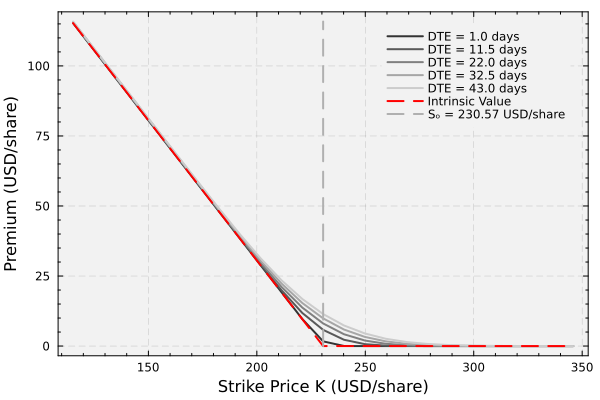

In [12]:
let

    # initialize -
    number_of_steps = 100;
    number_of_DTE_values = length(DTEV);
    colors = [RGB(0.2 + 0.6*(i-1)/(number_of_DTE_values-1), 0.2 + 0.6*(i-1)/(number_of_DTE_values-1), 0.2 + 0.6*(i-1)/(number_of_DTE_values-1)) for i in 1:number_of_DTE_values];

    # initialize -
    (number_of_strike_prices, number_of_DTE_values) = size(premium_matrix);
    fig = plot();
    for i ∈ 1:number_of_DTE_values
        DTE_value = DTEV[i];
        plot!(fig, SPV, premium_matrix[:,i], label="DTE = $(round(DTE_value, digits=1)) days", lw=2, c=colors[i]);
    end

    plot!(fig, intrinsic_array[:,1], intrinsic_array[:,2], 
        label="Intrinsic Value", lw=2, ls=:dash, color=:red);

    # current share price line -
    VLINE = zeros(number_of_steps, 2)
    VLINE[:,1] .= Sₒ*ones(number_of_steps)
    VLINE[:,2] .= range(0, stop = maximum(premium_matrix), length = number_of_steps) |> collect;
    plot!(VLINE[:,1], VLINE[:,2], lw=2, c= :gray69, ls=:dash, label="Sₒ = $(Sₒ) USD/share")

    plot!(bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent, 
        xminorticks=true, yminorticks=true, grid = :both, gridstyle = :dash, legend=:topright);  
    xlabel!(fig, "Strike Price K (USD/share)");
    ylabel!(fig, "Premium (USD/share)");

    display(fig)

    # uncomment to save this figure -
    # savefig(fig, joinpath(_PATH_TO_FIGS, "CHEME-5660-L10a-Example-ExtrinsicValue-Fall-2026.svg"));
end

Let's read the extrinsic value $E_{V}$ (USD/share) at three strikes, one in the money, one near the share price, and one out of the money, for the shortest and the longest time to expiration:

In [13]:
let

    # initialize: the sweep strikes nearest 0.8Sₒ, Sₒ, and 1.2Sₒ -
    picks = [argmin(abs.(SPV .- f*Sₒ)) for f ∈ (0.8, 1.0, 1.2)];
    EVM = premium_matrix .- intrinsic_array[:,2]; # extrinsic value of every contract in the sweep (USD/share)

    df = DataFrame(
        strike         = round.(SPV[picks], digits = 2),
        intrinsic      = round.(intrinsic_array[picks,2], digits = 2),
        extrinsic_short = round.(EVM[picks,1], digits = 3),
        extrinsic_long  = round.(EVM[picks,end], digits = 3)
    );
    pretty_table(df;
        column_labels = ["strike K", "intrinsic value", "E_V at $(round(DTEV[1], digits=1)) days",
            "E_V at $(round(DTEV[end], digits=1)) days"],
        alignment = [:r, :r, :r, :r], table_format = TextTableFormat(borders = text_table_borders__compact),
        fit_table_in_display_horizontally = false);

    # checks: extrinsic value is never negative, and the longer-dated contract carries at least as much -
    @assert all(EVM .≥ -1e-9) "a premium is below its intrinsic value"
    @assert all(EVM[:,end] .≥ EVM[:,1]) "a shorter-dated contract has more extrinsic value"
end

 ---------- ----------------- ----------------- ------------------
  strike K   intrinsic value   E_V at 1.0 days   E_V at 43.0 days 
 ---------- ----------------- ----------------- ------------------
    182.53             48.04             0.021              1.079
    230.57               0.0             1.674             11.425
    278.61               0.0               0.0              0.761
 ---------- ----------------- ----------------- ------------------


### Discussion
* __Hmmmm__. The long-dated contracts have higher premiums than the short-dated contracts at the same strike, even though their intrinsic values are identical. Why is this the case?
* __Curious__. Why does the premium approach the intrinsic value far away from the share price, i.e., out of the money (for very high strike prices), or deep in the money (for very low strike prices) for a call option contract? Deep in the money, the two do not quite meet: what is the residual gap, and what does it have to do with the strike being paid later rather than now?
___

## Summary
This example demonstrates how option premiums split into intrinsic and extrinsic components, and how extrinsic value responds to changes in time to expiration and strike price.

> __Key Takeaways:__
>
> * __Extrinsic value represents time value:__ The difference between an option's premium and its intrinsic value is the extrinsic value, which reflects the potential for favorable price movement over the remaining time until expiration. For an out-of-the-money call, the intrinsic value is zero, so the whole premium is extrinsic value.
> * __Time decay affects extrinsic value:__ Options with longer time to expiration have greater extrinsic value than shorter-dated options with the same strike, even when intrinsic values are identical. This reflects the greater opportunity for the underlying price to move favorably.
> * __Moneyness influences value decomposition:__ At-the-money and near-the-money options carry the largest extrinsic value, while deep out-of-the-money or deep in-the-money options have premiums that approach their intrinsic values with little extrinsic value.

Understanding the components of option value provides insight into how market expectations and time affect option pricing.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___